# HW4 final portfolio backtest

Run all cells from a fresh **Python (HW4)** kernel. The notebook builds its own point-in-time data, FF5 factors, HMM volume inputs, strategies, and portfolio. It does not depend on saved variables or outputs from `Research.ipynb`.

This notebook evaluates the two enabled components on the **full homework universe** over the assignment's final-test window:

- Development: **2010-01-01 to 2015-12-31**
- Buffer: **2016-01-01 to 2016-03-31**
- Final test: **2016-04-01 to 2026-09-30**

Components:

- `FactorTiltStrategy`: FF5 regression tilt.
- `HMMVolumeStrategy`: walk-forward volume-bar HMM overlay.

The portfolio layer is ERC. The benchmark is `^SP500TR` invested at the first test close. The notebook reports the required metrics, plots component and portfolio equity curves, shows portfolio weights through time, and runs explicit checks for the homework's backtesting rules.

## Important result limitation: stale holdings

The simulation completed the assigned **2016-04-01 to 2026-09-30** interval, but this run is not yet reliable evidence of final portfolio performance. The configuration allowed stale valuation marks for up to 10,000 sessions. The completed run reports **234,681 stale marks** and **16,328 open lots** at the end. These are carried valuations, not observed executions, and they can materially distort NAV and the strategy/benchmark comparison. Missing-price holdings need a justified, assignment-compliant resolution before these metrics are presented as definitive. The notebook preserves the run and its checks for review; the stale-mark count is disclosed in the compliance output below.

## Pending-sale lookup used in this run

The OMS checks for duplicate maturity orders through a lot-ID index while keeping the full order ledger. Maturities, observed execution quotes, accounting, and strategy decisions use the same engine rules. The indexed implementation is in `backtesting/indexed_sales.py`.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'pyproject.toml').is_file())
submission = root / 'Homeworks/HW4/David_MartinsHuber'
if str(submission) not in sys.path:
    sys.path.insert(0, str(submission))

from backtesting import MarketData, FamaFrench5, ERCOptimizer, BacktestAnalytics
from research.market import build_market_series, load_market_cap_frame
from strategies import FactorTiltStrategy, HMMVolumeStrategy

from backtesting.indexed_sales import ShadowPortfolioBacktester


## 1. Explicit configuration

The database stays read-only and outside Git. The final test uses the full universe through `2026-09-30`. A pre-test shadow warm-up starts in October 2015, before the final test, so ERC and both strategies have completed history at the test start.

In [2]:
DATABASE = submission / 'data/equities_top2000.duckdb'
DATA_END = '2026-09-30'
DEVELOPMENT_START, DEVELOPMENT_END = '2010-01-01', '2015-12-31'
BUFFER_START, BUFFER_END = '2016-01-01', '2016-03-31'
TEST_START, TEST_END = '2016-04-01', '2026-09-30'
SHADOW_START = '2015-10-01'
INITIAL_CASH = 1_000_000
FEE_BPS = 5
# The homework universe includes inactive names. The engine records stale
# marks for held names without a current quote; this limit lets the run reach
# the test end without inventing a liquidation fill. The limitation is printed
# in the compliance section.
MAX_STALE_SESSIONS = 10_000
started = time.perf_counter()

## 2. Build point-in-time inputs

The full homework universe is used; no current-active or survivorship screen is applied. `MarketData` preserves price history and applies the availability-aware currency filter. FF5 characteristics and the HMM volume proxy use only information available at each formation date.

In [3]:
data = MarketData.load(DATABASE, end=DATA_END)
factor_result = FamaFrench5().build(data, start='2005-01-01', end=DATA_END)
hmm_markets = build_market_series(DATABASE, end=DATA_END)
hmm_price, hmm_volume = hmm_markets['benchmark'].aligned()
market_caps = load_market_cap_frame(DATABASE, end=DATA_END)

display(data.coverage)
print('HMM market caps:', market_caps.shape)
print('HMM benchmark:', hmm_price.index.min().date(), '->', hmm_price.index.max().date())
print('Input construction seconds:', round(time.perf_counter() - started, 2))

/Users/davidhuber/Desktop/berkeley prequesites/Preprogram/UCB-MFE-python-preprogram-2026-winter/Homeworks/HW4/David_MartinsHuber/backtesting/market_data.py:142: UserWarning: Quarantining 275 invalid adjusted-price rows; inspect the raw database and delivery audit.
  prices, fundamentals, universe, benchmark = load_data(database, end=end, symbols=symbols)


/Users/davidhuber/Desktop/berkeley prequesites/Preprogram/UCB-MFE-python-preprogram-2026-winter/Homeworks/HW4/David_MartinsHuber/backtesting/market_data.py:142: UserWarning: Quarantining 28 price rows outside the supplied market calendar; inspect the raw database and delivery audit.
  prices, fundamentals, universe, benchmark = load_data(database, end=end, symbols=symbols)


price_start                  2000-01-03 00:00:00
price_end                    2026-09-30 00:00:00
sessions                                    6726
price_symbols                               3849
fundamental_symbols                         3849
non_usd_dropped         none (history preserved)
non_usd_known_at_end                         GFL
currency_filter               availability-aware
dtype: object

HMM market caps: (195970, 4)
HMM benchmark: 2000-01-03 -> 2026-09-30
Input construction seconds: 59.5


## 3. ERC portfolio with factor and HMM components

The enabled components are the FF5 factor tilt and the HMM volume strategy. Both are self-fitting and hold every purchase to the engine's 90-calendar-day maturity. The portfolio allocator is ERC; no extra main-account risk controls are enabled in this demonstration.

In [4]:
components = [
    FactorTiltStrategy(factor_result, window=60, min_obs=24, ramp_months=3, strategy_id='ff5_tilt'),
    HMMVolumeStrategy(
        hmm_price, hmm_volume,
        market_cap=market_caps,
        top_n=50,
        strategy_id='hmm_volume',
    ),
]
runner = ShadowPortfolioBacktester(
    market_data=data, shadows=components,
    optimizer=ERCOptimizer(lookback=63, min_observations=20, shrinkage=0.1),
    initial_cash=INITIAL_CASH, shadow_initial_cash=INITIAL_CASH,
    fee_bps=FEE_BPS, max_stale_sessions=MAX_STALE_SESSIONS,
)
bundle = runner.run(TEST_START, TEST_END, shadow_start=SHADOW_START)
assert set(bundle.shadows) == {s.strategy_id for s in components}
display(bundle.portfolio.coverage)
print('Total final-test seconds:', round(time.perf_counter() - started, 2))

Backtest progress: {"simulated_date": "2016-04-01", "completed_sessions": 1, "total_sessions": 2640, "percent_sessions": 0.04, "elapsed_seconds": 23.6}


Backtest progress: {"simulated_date": "2016-06-29", "completed_sessions": 63, "total_sessions": 2640, "percent_sessions": 2.39, "elapsed_seconds": 39.2}


Backtest progress: {"simulated_date": "2016-09-28", "completed_sessions": 126, "total_sessions": 2640, "percent_sessions": 4.77, "elapsed_seconds": 57.9}


Backtest progress: {"simulated_date": "2016-12-28", "completed_sessions": 189, "total_sessions": 2640, "percent_sessions": 7.16, "elapsed_seconds": 76.6}


Backtest progress: {"simulated_date": "2017-03-30", "completed_sessions": 252, "total_sessions": 2640, "percent_sessions": 9.55, "elapsed_seconds": 96.2}


Backtest progress: {"simulated_date": "2017-06-29", "completed_sessions": 315, "total_sessions": 2640, "percent_sessions": 11.93, "elapsed_seconds": 115.3}


... (35 outputs left out)

Backtest progress: {"simulated_date": "2026-07-10", "completed_sessions": 2583, "total_sessions": 2640, "percent_sessions": 97.84, "elapsed_seconds": 1593.2}


Backtest progress: {"simulated_date": "2026-09-30", "completed_sessions": 2640, "total_sessions": 2640, "percent_sessions": 100.0, "elapsed_seconds": 1626.9}


requested_start         2016-04-01 00:00:00
requested_end           2026-09-30 00:00:00
effective_start         2016-04-01 00:00:00
effective_end           2026-09-30 00:00:00
initial_capital_date    2016-03-31 00:00:00
range_clipped                         False
dtype: object

Total final-test seconds: 1768.75


## 4. Component and portfolio analysis

Each shadow is analyzed separately first. Shadow histories include the pre-test warm-up, so their full-history metrics are not directly comparable to the main test-period metrics. The combined equity-curve chart is aligned at the first test close.

=== ff5_tilt ===


,Strategy,S&P 500 total return
final_value,2.658984e+06,4.796801e+06
total_return,1.658984e+00,3.796801e+00
CAGR,9.296968e-02,1.531899e-01
max_drawdown,-3.130845e-01,-3.379046e-01
Sharpe,4.592521e-01,7.821950e-01
annualized_volatility,1.907060e-01,1.776611e-01
annualized_alpha,-4.760939e-02,0.000000e+00
beta,9.728414e-01,1.000000e+00
VaR_95_daily,1.847227e-02,1.638432e-02
VaR_99_daily,3.377665e-02,3.234454e-02


,order_id,lot_id,strategy_id,trigger,model_version,symbol,side,signal_date,date,due_date,price,units,notional,fee,cash_change,realized_pnl
0,0,0,ff5_tilt,strategy,1,A,BUY,2015-09-30,2015-10-01,2015-12-30,31.000000,6.636699,205.737682,0.102869,-205.840550,0.0
1,1,1,ff5_tilt,strategy,1,AAIC,BUY,2015-09-30,2015-10-01,2015-12-30,7.102960,0.819794,5.822966,0.002911,-5.825878,0.0
2,2,2,ff5_tilt,strategy,1,AAL,BUY,2015-09-30,2015-10-01,2015-12-30,37.380684,13.188891,493.009783,0.246505,-493.256288,0.0
3,3,3,ff5_tilt,strategy,1,AAN,BUY,2015-09-30,2015-10-01,2015-12-30,36.320000,1.301637,47.275447,0.023638,-47.299085,0.0
4,4,4,ff5_tilt,strategy,1,AAOI,BUY,2015-09-30,2015-10-01,2015-12-30,18.040000,0.296468,5.348276,0.002674,-5.350950,0.0


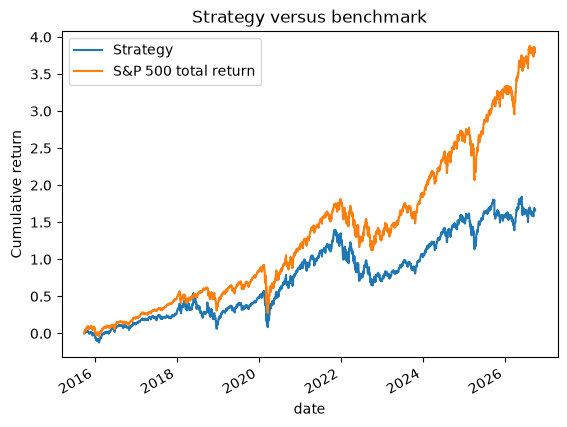

=== hmm_volume ===


,Strategy,S&P 500 total return
final_value,2.470258e+06,4.796801e+06
total_return,1.470258e+00,3.796801e+00
CAGR,8.567948e-02,1.531899e-01
max_drawdown,-6.305275e-01,-3.379046e-01
Sharpe,3.526546e-01,7.821950e-01
annualized_volatility,3.119372e-01,1.776611e-01
annualized_alpha,-3.267742e-03,0.000000e+00
beta,8.151211e-01,1.000000e+00
VaR_95_daily,2.669815e-02,1.638432e-02
VaR_99_daily,5.011624e-02,3.234454e-02


,order_id,lot_id,strategy_id,trigger,model_version,symbol,side,signal_date,date,due_date,price,units,notional,fee,cash_change,realized_pnl
0,0,0,hmm_volume,strategy,1,TMBR,BUY,2015-09-30,2015-10-01,2015-12-30,1.367500e+03,390.991404,534680.744359,267.340372,-534948.084731,0.0
1,1,1,hmm_volume,strategy,1,KDNY,BUY,2015-09-30,2015-10-01,2015-12-30,9.745000e+01,1407.211497,137132.760408,68.566380,-137201.326788,0.0
2,2,2,hmm_volume,strategy,1,BKNG,BUY,2015-09-30,2015-10-01,2015-12-30,1.238170e+03,34.947532,43270.985356,21.635493,-43292.620849,0.0
3,3,3,hmm_volume,strategy,1,INPX,BUY,2015-09-30,2015-10-01,2015-12-30,1.681384e+09,0.000015,26050.152788,13.025076,-26063.177865,0.0
4,4,4,hmm_volume,strategy,1,AAPL,BUY,2015-09-30,2015-10-01,2015-12-30,2.456000e+01,697.349559,17126.905169,8.563453,-17135.468621,0.0


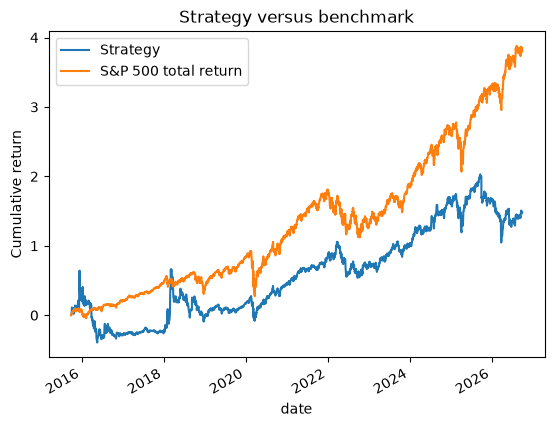

,final_value,total_return,CAGR,max_drawdown,Sharpe,annualized_volatility,annualized_alpha,beta,VaR_95_daily,VaR_99_daily,daily_observations
ff5_tilt,2.658984e+06,1.658984,0.092970,-0.313085,0.459252,0.190706,-0.047609,0.972841,0.018472,0.033777,2765.0
hmm_volume,2.470258e+06,1.470258,0.085679,-0.630527,0.352655,0.311937,-0.003268,0.815121,0.026698,0.050116,2765.0


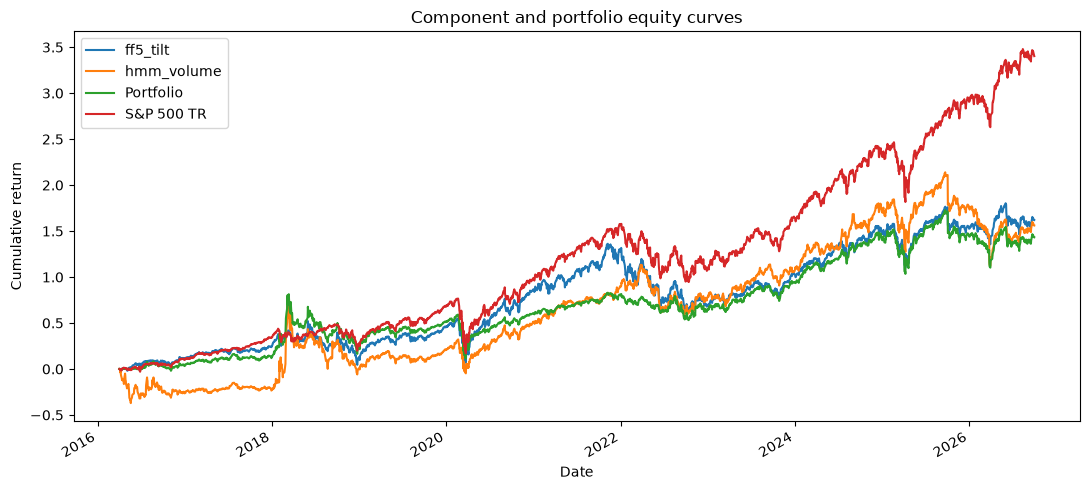

In [5]:
history, fills = bundle.portfolio.history, bundle.portfolio.fills
np.testing.assert_allclose(history.nav, history.cash + history.holdings_value)
assert history.cash.ge(0).all()
if not fills.empty:
    buys, sales = fills.loc[fills.side.eq('BUY')], fills.loc[fills.side.eq('SELL')]
    assert buys.signal_date.lt(buys.date).all()
    assert sales.date.ge(sales.due_date).all()
    assert sales.trigger.eq('maturity').all()
    cash_changes = fills.groupby('date').cash_change.sum().reindex(history.index, fill_value=0)
    np.testing.assert_allclose(history.cash, INITIAL_CASH + cash_changes.cumsum(), atol=1e-6)

component_summary = {}
for name, result in bundle.shadows.items():
    print(f'=== {name} ===')
    analytics = BacktestAnalytics(result, annual_rf=0.02)
    summary = analytics.summary()
    component_summary[name] = summary['Strategy']
    display(summary)
    display(result.fills.head())
    analytics.plot_cumulative_returns()
    plt.show()

display(pd.DataFrame(component_summary).T)

# Combined equity curves aligned at the first test close.
test_days = history.index[1:]
curves = pd.DataFrame({
    'ff5_tilt': bundle.shadows['ff5_tilt'].history.nav,
    'hmm_volume': bundle.shadows['hmm_volume'].history.nav,
    'Portfolio': history.nav,
    'S&P 500 TR': history.benchmark_nav,
}).reindex(test_days).ffill()
curves = curves / curves.iloc[0] - 1
ax = curves.plot(figsize=(11, 5), title='Component and portfolio equity curves')
ax.set_xlabel('Date')
ax.set_ylabel('Cumulative return')
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

## 5. Portfolio-level analysis

Required homework metrics for the main portfolio and the S&P 500 total-return benchmark: final value, CAGR, maximum drawdown, Sharpe at a 2% annual risk-free rate, and the cumulative-return comparison.

,Strategy,S&P 500 total return
final_value,2.432336e+06,4.402747e+06
total_return,1.432336e+00,3.402747e+00
CAGR,8.834191e-02,1.516195e-01
max_drawdown,-3.862680e-01,-3.379046e-01
Sharpe,4.502921e-01,7.725008e-01
annualized_volatility,1.806649e-01,1.781782e-01
annualized_alpha,-2.599240e-02,5.464379e-17
beta,7.798764e-01,1.000000e+00
VaR_95_daily,1.499116e-02,1.636892e-02
VaR_99_daily,3.287540e-02,3.268215e-02


strategy_final_value          2432336.415114
benchmark_final_value         4402746.776271
final_value_difference       -1970410.361157
total_return_difference_pp       -197.041036
beat_benchmark                         False
dtype: object

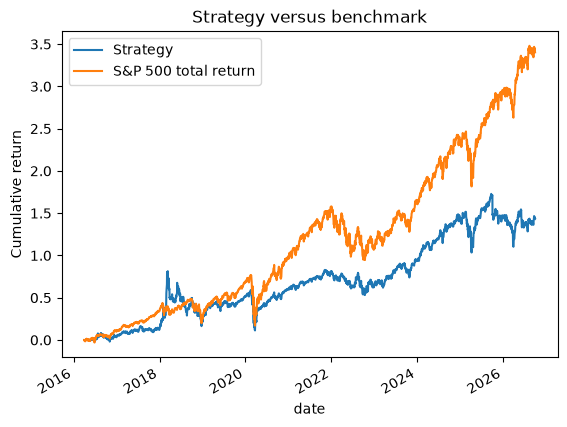

,date,symbol,event
1924993,2026-09-30,NUVL,maturity_exit_delayed
1924994,2026-09-30,OLPX,maturity_exit_delayed
1924995,2026-09-30,SEM,maturity_exit_delayed
1924996,2026-09-30,SKYT,maturity_exit_delayed
1924997,2026-09-30,TMHC,maturity_exit_delayed


,lot_id,strategy_id,symbol,units,entry_date,entry_price,entry_fee,due_date,model_version
0,1230,portfolio,NTI,2.025531,2016-06-01,21.68,0.021957,2016-08-30,0
1,3079,portfolio,NTI,0.166011,2016-06-09,21.41,0.001777,2016-09-07,0
2,4204,portfolio,NTI,0.084693,2016-06-21,20.89,0.000885,2016-09-19,0
3,5152,portfolio,DWRE,0.344650,2016-07-06,74.99,0.012923,2016-10-04,0
4,6057,portfolio,DWRE,0.038343,2016-07-08,74.97,0.001437,2016-10-06,0


In [6]:
portfolio_analysis = BacktestAnalytics(bundle.portfolio, annual_rf=0.02)
display(portfolio_analysis.summary())
display(portfolio_analysis.comparison())
portfolio_analysis.plot_cumulative_returns()
plt.show()
display(bundle.portfolio.diagnostics.tail())
display(bundle.portfolio.open_lots.head())

## 6. Portfolio weights through time

ERC weights are recorded at every signal date. The table and stacked area chart show how capital is allocated across the component strategies through time.

component_id,ff5_tilt,hmm_volume
signal_date,,
2026-09-01,0.484574,0.515426
2026-09-02,0.484776,0.515224
2026-09-03,0.486232,0.513768
2026-09-04,0.486874,0.513126
2026-09-08,0.466508,0.533492
2026-09-09,0.465594,0.534406
2026-09-10,0.463581,0.536419
2026-09-11,0.468333,0.531667
2026-09-14,0.467452,0.532548


,average_weight
component_id,
ff5_tilt,0.552824
hmm_volume,0.447176


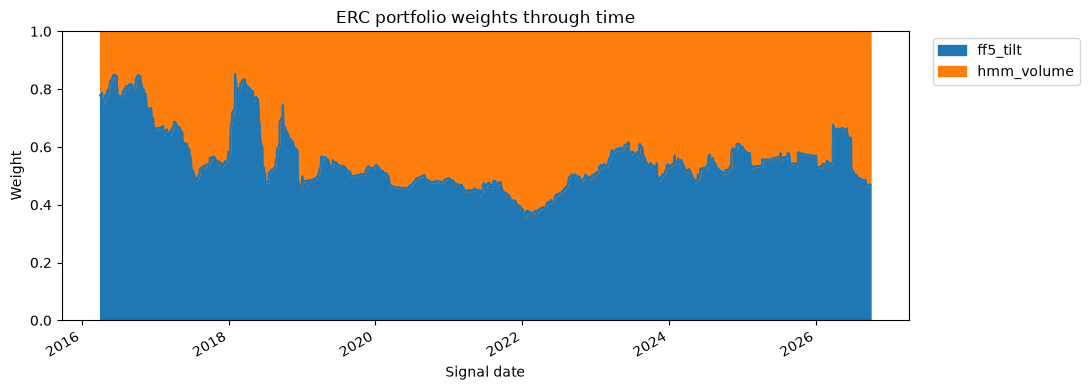

In [7]:
weights = (bundle.allocations
           .pivot_table(index='signal_date', columns='component_id',
                        values='weight', aggfunc='sum')
           .sort_index()
           .fillna(0.0))
weights = weights.loc[weights.index >= pd.Timestamp(TEST_START)]
np.testing.assert_allclose(weights.sum(axis=1), 1.0, atol=1e-8)
display(weights.tail(20))
display(weights.mean().to_frame('average_weight'))

ax = weights.plot.area(figsize=(11, 4), stacked=True)
ax.set_title('ERC portfolio weights through time')
ax.set_xlabel('Signal date')
ax.set_ylabel('Weight')
ax.set_ylim(0, 1)
ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

## 7. Homework backtesting compliance checks

These assertions verify the assignment rules: $1,000,000 starting capital, long-only, no borrowing, next-session entries, 90-calendar-day maturities, cash accounting, full-period coverage, and the benchmark starting at the first test close. Stale held marks are reported as a data limitation.

In [8]:
coverage = bundle.portfolio.coverage
assert pd.Timestamp(coverage.requested_start) == pd.Timestamp(TEST_START)
assert pd.Timestamp(coverage.requested_end) == pd.Timestamp(TEST_END)
assert not bool(coverage.range_clipped)
assert history.index[-1] == pd.Timestamp(TEST_END)
assert data.calendar.max() == pd.Timestamp(TEST_END)
assert history.nav.iloc[0] == INITIAL_CASH
assert history.benchmark_nav.iloc[0] == INITIAL_CASH
assert np.isfinite(history[['nav', 'cash', 'holdings_value', 'benchmark_nav']].to_numpy()).all()
assert (history.cash >= 0).all()
assert np.allclose(history.nav, history.cash + history.holdings_value)

buys = fills.loc[fills.side.eq('BUY')]
sales = fills.loc[fills.side.eq('SELL')]
assert set(fills.side).issubset({'BUY', 'SELL'})
assert (buys.signal_date < buys.date).all()
assert (buys.due_date == buys.date + pd.Timedelta(days=90)).all()
assert sales.trigger.eq('maturity').all()
assert (sales.date >= sales.due_date).all()
assert (bundle.portfolio.open_lots.units > 0).all()

benchmark = data.benchmark.set_index('date').adj_close
first_test = history.index[1]
expected_benchmark = INITIAL_CASH * benchmark.loc[pd.Timestamp(TEST_END)] / benchmark.loc[first_test]
assert np.isclose(history.benchmark_nav.iloc[-1], expected_benchmark, rtol=1e-12, atol=1e-8)

stale = bundle.portfolio.diagnostics.loc[bundle.portfolio.diagnostics.event.eq('stale_mark')]
print('observed stale held marks:', len(stale), 'symbols:', sorted(stale.symbol.unique()))
print('holding-period sales:', len(sales), 'open lots at end:', len(bundle.portfolio.open_lots))
print('compliance checks passed')
display(pd.Series({
    'start_capital': INITIAL_CASH,
    'final_nav': history.nav.iloc[-1],
    'benchmark_final_nav': history.benchmark_nav.iloc[-1],
    'sessions': len(history) - 1,
    'fills': len(fills),
    'stale_marks': len(stale),
    'max_stale_sessions': MAX_STALE_SESSIONS,
    'fee_bps': FEE_BPS,
}, name='value'))

observed stale held marks: 234681 symbols: ['AAM', 'AAWW', 'ABC', 'ACC', 'ACLX', 'AEPPZ', 'AGR', 'AIMC', 'AIRC', 'AJRD', 'AKRO', 'AL', 'ALE', 'ALEX', 'ALJ', 'ALPN', 'ALTR', 'ALXN', 'AMEH', 'ANSS', 'ANTM', 'APGE', 'APLS', 'AQNA', 'AQUA', 'ARCH', 'ARNA', 'ARNC', 'ATAI', 'ATGE', 'ATSG', 'ATVI', 'AVDX', 'AVGOP', 'AVNS', 'AVPTW', 'AYX', 'AZEK', 'AZPN', 'BASE', 'BDXA', 'BDXB', 'BECN', 'BERY', 'BH-A', 'BIO-B', 'BKDT', 'BKI', 'BLD', 'BLL', 'BOWL', 'BPMC', 'BRKS', 'BVH', 'CBAY', 'CCCS', 'CCF', 'CCLDO', 'CCMP', 'CCZ', 'CDAY', 'CDEV', 'CDK', 'CDTX', 'CEIX', 'CEQP', 'CEQP-P', 'CERE', 'CERN', 'CFLT', 'CFX', 'CFXA', 'CHK', 'CHKEL', 'CHKEW', 'CHNG', 'CHNGU', 'CHX', 'CIVI', 'CLI', 'CLR', 'CNST', 'CONE', 'CPRX', 'CREE', 'CRNX', 'CSGS', 'CSOD', 'CST', 'CSWI', 'CTLT', 'CTRA', 'CTXS', 'CUK', 'CVA', 'CVT', 'CWAN', 'CWEN-A', 'CXP', 'DAWN', 'DAY', 'DCP', 'DCPH', 'DCUE', 'DEN', 'DO', 'DOOR', 'DRE', 'DTP', 'DVAX', 'DWRE', 'EA', 'ECOL', 'EDR', 'ELY', 'ENBA', 'ENFN', 'ENLC', 'ENV', 'EPAY', 'ESTE', 'ETNB', 'ETRN'

start_capital          1.000000e+06
final_nav              2.432336e+06
benchmark_final_nav    4.402747e+06
sessions               2.640000e+03
fills                  8.560720e+05
stale_marks            2.346810e+05
max_stale_sessions     1.000000e+04
fee_bps                5.000000e+00
Name: value, dtype: float64

## 8. HMM volume component diagnostics

The HMM component is a full self-fitting strategy inside the shadow portfolio.
It uses the S&P 500 benchmark and effective-universe volume proxy, refits its
3-state HMM walk-forward, and submits risk-on baskets. Existing lots are held
to the engine's 90-calendar-day maturity.


In [9]:

hmm_shadow = bundle.shadows['hmm_volume']
display(hmm_shadow.performance())
display(hmm_shadow.refits.tail())
display(hmm_shadow.fills.head())
display(
    bundle.contributions.loc[
        bundle.contributions.component_id.eq('hmm_volume')
    ].head()
)


,Strategy,S&P 500 total return
final_value,2.470258e+06,4.796801e+06
total_return,1.470258e+00,3.796801e+00
CAGR,8.567948e-02,1.531899e-01
max_drawdown,-6.305275e-01,-3.379046e-01
Sharpe,3.526546e-01,7.821950e-01
annualized_volatility,3.119372e-01,1.776611e-01
annualized_alpha,-3.267742e-03,0.000000e+00
beta,8.151211e-01,1.000000e+00
VaR_95_daily,2.669815e-02,1.638432e-02
VaR_99_daily,5.011624e-02,3.234454e-02


,signal_date,model_version,rows,first_date,last_date,latest_label_end,latest_available,settings,status
36,2025-08-14,37,0,NaT,NaT,NaT,NaT,"{'median_window': 90, 'bucket_multiple': 5.0, ...",success
37,2025-11-18,38,0,NaT,NaT,NaT,NaT,"{'median_window': 90, 'bucket_multiple': 5.0, ...",success
38,2026-03-05,39,0,NaT,NaT,NaT,NaT,"{'median_window': 90, 'bucket_multiple': 5.0, ...",success
39,2026-06-16,40,0,NaT,NaT,NaT,NaT,"{'median_window': 90, 'bucket_multiple': 5.0, ...",success
40,2026-09-28,41,0,NaT,NaT,NaT,NaT,"{'median_window': 90, 'bucket_multiple': 5.0, ...",success


,order_id,lot_id,strategy_id,trigger,model_version,symbol,side,signal_date,date,due_date,price,units,notional,fee,cash_change,realized_pnl
0,0,0,hmm_volume,strategy,1,TMBR,BUY,2015-09-30,2015-10-01,2015-12-30,1.367500e+03,390.991404,534680.744359,267.340372,-534948.084731,0.0
1,1,1,hmm_volume,strategy,1,KDNY,BUY,2015-09-30,2015-10-01,2015-12-30,9.745000e+01,1407.211497,137132.760408,68.566380,-137201.326788,0.0
2,2,2,hmm_volume,strategy,1,BKNG,BUY,2015-09-30,2015-10-01,2015-12-30,1.238170e+03,34.947532,43270.985356,21.635493,-43292.620849,0.0
3,3,3,hmm_volume,strategy,1,INPX,BUY,2015-09-30,2015-10-01,2015-12-30,1.681384e+09,0.000015,26050.152788,13.025076,-26063.177865,0.0
4,4,4,hmm_volume,strategy,1,AAPL,BUY,2015-09-30,2015-10-01,2015-12-30,2.456000e+01,697.349559,17126.905169,8.563453,-17135.468621,0.0


,signal_date,execution_date,component_id,symbol,budget,model_version
292,2016-04-11,2016-04-12,hmm_volume,TMBR,352.142411,2
293,2016-04-11,2016-04-12,hmm_volume,IVR,183.822505,2
294,2016-04-11,2016-04-12,hmm_volume,KDNY,56.440971,2
295,2016-04-11,2016-04-12,hmm_volume,BKNG,19.954178,2
296,2016-04-11,2016-04-12,hmm_volume,AAM,7.999209,2
